<a href="https://colab.research.google.com/github/Danylo5051/machine-learning-lectures4-9/blob/main/%D0%A1%D0%B0%D1%82%D0%BA%D0%BE%D0%94_4%D0%BA9%D0%B3%D0%9B%D0%B5%D0%BA%D1%86%D1%96%D1%8F_%D0%9A%D0%BB%D0%B0%D1%81%D1%82%D0%B5%D1%80%D0%B8%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%9C%D0%9D_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Тренувальний ноутбук до лекції «Кластеризація даних у машинному навчанні»

**Дисципліна:** Машинне навчання  
**Формат:** практична демонстрація теоретичних положень лекції; Python / Jupyter Notebook / Google Colab.

**Мета:** навчитися готувати ознаки, застосовувати основні алгоритми кластеризації, обґрунтовано визначати кількість кластерів, оцінювати результати й інтерпретувати їх.

**Що буде розглянуто:**
1. Метрики відстані, стандартизація та PCA.
2. K-means, MiniBatchKMeans, BisectingKMeans.
3. Вибір $K$: лікоть, силует, Calinski–Harabasz, Davies–Bouldin, `KneeLocator` та `KElbowVisualizer`.
4. Агломеративна кластеризація та дендрограма.
5. DBSCAN, OPTICS, HDBSCAN і визначення щільнісних груп.
6. Mean Shift, Affinity Propagation, BIRCH, Spectral Clustering.
7. Gaussian Mixture Models, AIC/BIC і BayesianGaussianMixture.
8. Наскрізний аналіз Wine, перевірка якості та інтерпретація сегментів.
9. **Одне самостійне завдання** наприкінці.

> Усі основні приклади працюють на вбудованих наборах даних `scikit-learn`; зовнішні CSV-файли не потрібні. Дані про опосумів із лабораторної роботи **не використовуються**. Для відтворюваності застосовуємо `random_state=42`.

## 0. Середовище та імпорт бібліотек

**Відповідність лекції:** розділи 2, 3, 8, 11. У Google Colab достатньо послідовно виконати комірки. Для більшості демонстрацій потрібні лише `numpy`, `pandas`, `matplotlib`, `scipy` та `scikit-learn`.

*Окремо:* `kneed` і `yellowbrick` — додаткові пакети, а не вбудовані функції `scikit-learn`. Їхні демонстрації не перериватимуть виконання ноутбука, якщо пакети ще не встановлені.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import scipy

from sklearn.datasets import load_iris, load_wine, make_blobs, make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import (
    KMeans, MiniBatchKMeans, BisectingKMeans,
    AgglomerativeClustering, DBSCAN, OPTICS, HDBSCAN,
    MeanShift, estimate_bandwidth, AffinityPropagation,
    Birch, SpectralClustering,
)
from sklearn.mixture import GaussianMixture, BayesianGaussianMixture
from sklearn.metrics import (
    silhouette_score, silhouette_samples,
    calinski_harabasz_score, davies_bouldin_score,
    adjusted_rand_score, adjusted_mutual_info_score,
)
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import euclidean, cityblock, cosine

RANDOM_STATE = 42
pd.set_option('display.max_columns', 15)
plt.rcParams.update({'figure.figsize': (8, 5), 'axes.grid': True,
                     'grid.alpha': 0.20, 'font.size': 10})

print('scikit-learn:', sklearn.__version__)
print('NumPy:', np.__version__)
print('SciPy:', scipy.__version__)

scikit-learn: 1.6.1
NumPy: 2.4.6
SciPy: 1.16.3


## 1. Що означає «схожість» у кластеризації?

**Відповідність лекції:** §1–2.

Нехай два об'єкти подано векторами ознак $x$ та $y$. Вибір відстані визначає, які об'єкти алгоритм вважатиме близькими:

- Евклідова: $d_2(x,y)=\sqrt{\sum_j(x_j-y_j)^2}$.
- Манхеттенська: $d_1(x,y)=\sum_j|x_j-y_j|$.
- Косинусна відстань: $1-\frac{x\cdot y}{\|x\|\|y\|}$.

Косинусна відстань більше зосереджена на напрямі, а не на абсолютній довжині вектора. Значення метрик **не можна** порівнювати між собою без урахування означення.

In [13]:
x = np.array([1.0, 4.0, 2.0])
y = np.array([2.0, 1.0, 5.0])
print(f'Евклідова відстань: {euclidean(x, y):.3f}')
print(f'Манхеттенська відстань: {cityblock(x, y):.3f}')
print(f'Косинусна відстань: {cosine(x, y):.3f}')

Евклідова відстань: 4.359
Манхеттенська відстань: 7.000
Косинусна відстань: 0.363


### 1.1. Завантаження Iris і стандартизація

У наборі **Iris** є 150 об'єктів із чотирма числовими ознаками. Для демонстрації кластеризації справжні видові мітки не використовуємо під час навчання. `StandardScaler` обчислює для кожної ознаки $z=(x-\mu)/\sigma$.

**Важливо:** перетворення масштабу ознак змінює відстані та може істотно змінити кластери. PCA нижче використовується **лише для двовимірного відображення**; алгоритм навчатиметься на всіх чотирьох стандартизованих ознаках.

Розмірність Iris: (150, 4)
Середні стандартизованих ознак: [-0. -0. -0. -0.]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


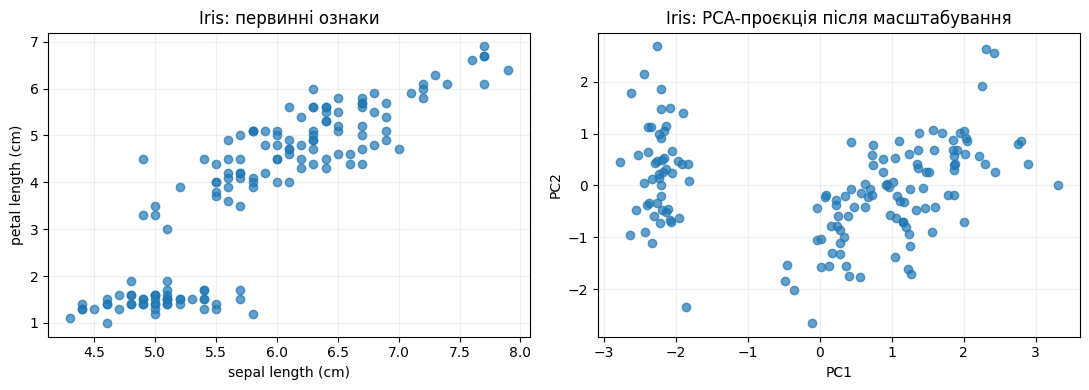

In [14]:
iris = load_iris(as_frame=True)
features_iris = iris.data.copy()
y_iris_reference = iris.target.to_numpy()  # лише для незалежної оцінки згодом

scaler_iris = StandardScaler()
X_iris = scaler_iris.fit_transform(features_iris)
X_iris_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_iris)

print('Розмірність Iris:', X_iris.shape)
print('Середні стандартизованих ознак:', np.round(X_iris.mean(axis=0), 3))
display(features_iris.head())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(features_iris.iloc[:, 0], features_iris.iloc[:, 2], alpha=0.7)
ax[0].set(title='Iris: первинні ознаки', xlabel=features_iris.columns[0],
          ylabel=features_iris.columns[2])
ax[1].scatter(X_iris_2d[:, 0], X_iris_2d[:, 1], alpha=0.7)
ax[1].set(title='Iris: PCA-проєкція після масштабування',
          xlabel='PC1', ylabel='PC2')
plt.tight_layout()
plt.show()

## 2. K-means: кластеризація навколо центрів

**Відповідність лекції:** §3.

K-means мінімізує суму квадратів відстаней від точок до центрів їхніх кластерів:

$$\operatorname{WCSS}=\sum_{k=1}^{K}\sum_{x_i\in C_k}\|x_i-\mu_k\|^2.$$

**Алгоритм:** ініціалізувати $K$ центрів → призначити кожну точку найближчому центру → перерахувати центри → повторювати до стабілізації. Значення `inertia_` у `sklearn.cluster.KMeans` відповідає WCSS для отриманого розбиття.

Кількість точок у кластерах: {0: 53, 1: 50, 2: 47}
WCSS / inertia_: 139.820
Розмірність центрів: (3, 4)


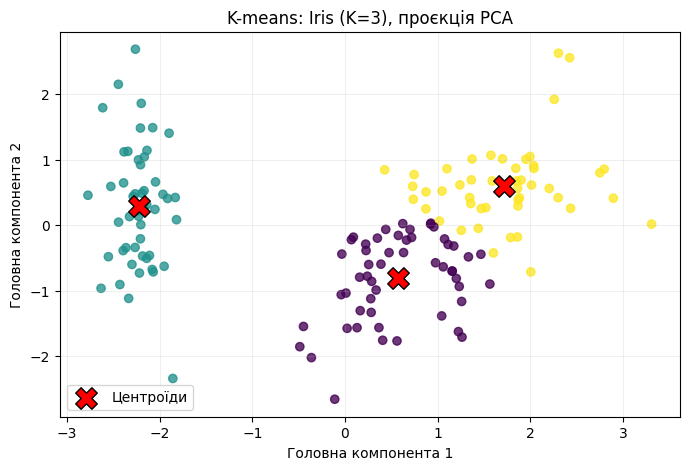

In [15]:
model_iris_km = KMeans(n_clusters=3, init='k-means++',
                        n_init=10, random_state=RANDOM_STATE)
labels_iris_km = model_iris_km.fit_predict(X_iris)

print('Кількість точок у кластерах:',
      pd.Series(labels_iris_km).value_counts().sort_index().to_dict())
print(f'WCSS / inertia_: {model_iris_km.inertia_:.3f}')
print('Розмірність центрів:', model_iris_km.cluster_centers_.shape)

pca_iris = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_iris)
centers_iris_2d = pca_iris.transform(model_iris_km.cluster_centers_)
projected_iris = pca_iris.transform(X_iris)

plt.scatter(projected_iris[:, 0], projected_iris[:, 1],
            c=labels_iris_km, cmap='viridis', alpha=0.78)
plt.scatter(centers_iris_2d[:, 0], centers_iris_2d[:, 1],
            color='red', marker='X', s=240, edgecolor='black', label='Центроїди')
plt.xlabel('Головна компонента 1')
plt.ylabel('Головна компонента 2')
plt.title('K-means: Iris (K=3), проєкція PCA')
plt.legend()
plt.show()

### 2.1. Варіанти K-means

`MiniBatchKMeans` оновлює центри на невеликих пакетах спостережень; `BisectingKMeans` ієрархічно ділить групи на дві частини. Це **не тотожні алгоритми**, тому їхні значення WCSS можуть відрізнятися. Порівняння доцільне на одних і тих самих ознаках.

In [16]:
alternatives = {
    'KMeans': KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE),
    'MiniBatchKMeans': MiniBatchKMeans(n_clusters=3, batch_size=32,
                                     n_init=10, random_state=RANDOM_STATE),
    'BisectingKMeans': BisectingKMeans(n_clusters=3, random_state=RANDOM_STATE)
}
rows = []
for name, estimator in alternatives.items():
    predicted = estimator.fit_predict(X_iris)
    rows.append({'Алгоритм': name, 'WCSS': estimator.inertia_,
                 'Silhouette': silhouette_score(X_iris, predicted),
                 'Розмірів груп': tuple(np.bincount(predicted))})
display(pd.DataFrame(rows).round(3))

,Алгоритм,WCSS,Silhouette,Розмірів груп
0,KMeans,139.820,0.460,"(53, 50, 47)"
1,MiniBatchKMeans,141.080,0.455,"(52, 50, 48)"
2,BisectingKMeans,140.033,0.463,"(50, 56, 44)"


## 3. Як обрати кількість кластерів K?

**Відповідність лекції:** §8.2–8.4.

Перейдемо до набору **Wine** (13 числових ознак). Заздалегідь задані категорії в наборі даних не використовуємо для вибору $K$.

- **Метод ліктя:** шукаємо уповільнення спадання `inertia_` (WCSS); мінімум WCSS без штрафу не визначає корисне $K$.
- **Silhouette:** більший середній силует означає кращу геометричну компактність і відокремленість.
- **Calinski–Harabasz (CH):** більший — кращий за відповідним критерієм.
- **Davies–Bouldin (DB):** менший — кращий за відповідним критерієм.

Silhouette, CH і DB потребують принаймні двох ненульових кластерів; для `K=1` їх не обчислюємо.

In [17]:
wine = load_wine(as_frame=True)
features_wine = wine.data.copy()
y_wine_reference = wine.target.to_numpy()  # не використовуємо під час навчання
scaler_wine = StandardScaler()
X_wine = scaler_wine.fit_transform(features_wine)

rows_k = []
for k in range(1, 10):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels = km.fit_predict(X_wine)
    row = {'K': k, 'WCSS': km.inertia_,
           'Silhouette': np.nan, 'CH': np.nan, 'DB': np.nan}
    if k >= 2:
        row['Silhouette'] = silhouette_score(X_wine, labels)
        row['CH'] = calinski_harabasz_score(X_wine, labels)
        row['DB'] = davies_bouldin_score(X_wine, labels)
    rows_k.append(row)

metrics_wine = pd.DataFrame(rows_k).set_index('K')
display(metrics_wine.round(3))

,WCSS,Silhouette,CH,DB
K,,,,
1,2314.000,NaN,NaN,NaN
2,1658.759,0.259,69.523,1.526
3,1277.928,0.285,70.940,1.389
4,1175.428,0.260,56.181,1.797
5,1109.513,0.202,46.952,1.808
6,1046.002,0.237,41.701,1.554
7,981.595,0.204,38.686,1.661
8,935.201,0.157,35.805,1.741
9,889.893,0.150,33.807,1.708


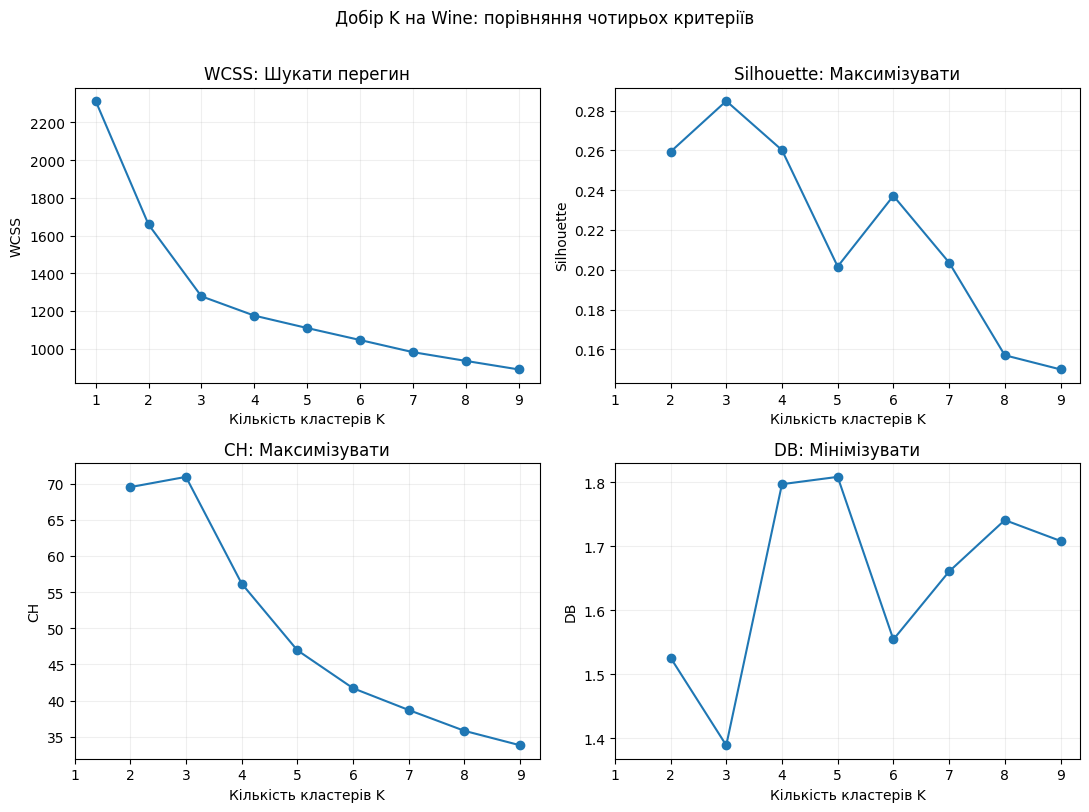

Кандидат за силуетом: 3
Кандидат за CH: 3
Кандидат за DB: 3


In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, metric, prefer in zip(
    axes.flat,
    ['WCSS', 'Silhouette', 'CH', 'DB'],
    ['Шукати перегин', 'Максимізувати', 'Максимізувати', 'Мінімізувати']
):
    ax.plot(metrics_wine.index, metrics_wine[metric], marker='o')
    ax.set(title=f'{metric}: {prefer}', xlabel='Кількість кластерів K',
           ylabel=metric)
    ax.set_xticks(metrics_wine.index)
fig.suptitle('Добір K на Wine: порівняння чотирьох критеріїв', y=1.01)
plt.tight_layout()
plt.show()

print('Кандидат за силуетом:', metrics_wine['Silhouette'].idxmax())
print('Кандидат за CH:', metrics_wine['CH'].idxmax())
print('Кандидат за DB:', metrics_wine['DB'].idxmin())

### 3.1. Силует для окремих об'єктів

Для точки $i$ величина $a(i)$ — середня відстань до точок її кластера, $b(i)$ — мінімальна середня відстань до іншого кластера. Тоді

$$s(i)=\frac{b(i)-a(i)}{\max\{a(i),b(i)\}}.$$

Близьке до 1 значення відповідає доброму відокремленню; близьке до 0 — прикордонному розташуванню; від'ємне може свідчити про неузгоджену належність. **Середній бал не показує форму розподілу**, тому корисно будувати силуетні профілі.

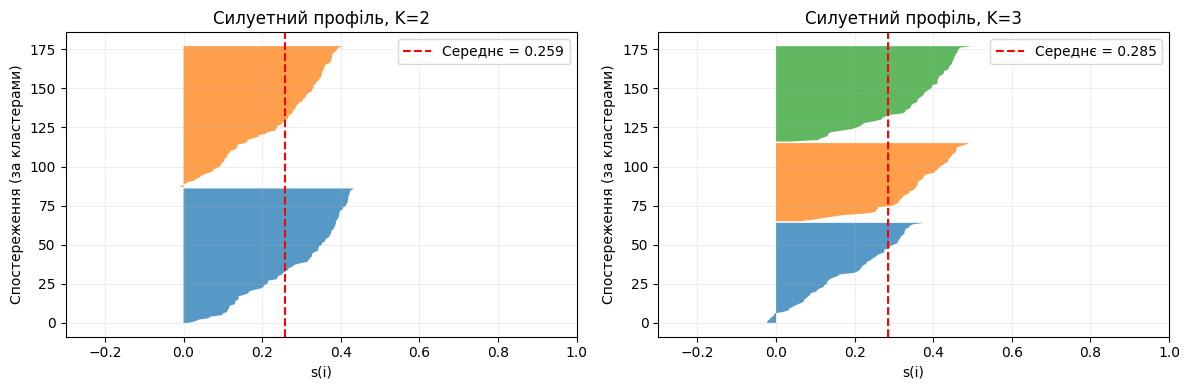

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k in zip(axes, [2, 3]):
    labels_k = KMeans(n_clusters=k, n_init=10,
                      random_state=RANDOM_STATE).fit_predict(X_wine)
    values = silhouette_samples(X_wine, labels_k)
    left = 0
    for group in np.unique(labels_k):
        group_values = np.sort(values[labels_k == group])
        right = left + len(group_values)
        ax.fill_betweenx(np.arange(left, right), 0, group_values, alpha=0.75)
        left = right
    ax.axvline(float(np.mean(values)), color='red', linestyle='--',
               label=f'Середнє = {np.mean(values):.3f}')
    ax.set(title=f'Силуетний профіль, K={k}', xlabel='s(i)',
           ylabel='Спостереження (за кластерами)', xlim=(-0.3, 1))
    ax.legend()
plt.tight_layout()
plt.show()

### 3.2. Допоміжна автоматизація: `kneed` і `yellowbrick`

Ці два інструменти **не є вбудованими у `sklearn`**. У Google Colab їх можна встановити, виконавши окрему комірку:

```python
%pip install kneed yellowbrick
```

`KneeLocator` шукає «коліно» кривої WCSS; він може повернути `None`, якщо перегину немає. `KElbowVisualizer` візуалізує оцінки для різних K та повертає `elbow_value_`. Інструменти дають **кандидатне**, а не абсолютне «правильне» число кластерів.

In [20]:
%pip install kneed yellowbrick

kneed → кандидат K: 3
Yellowbrick → кандидат K: 3


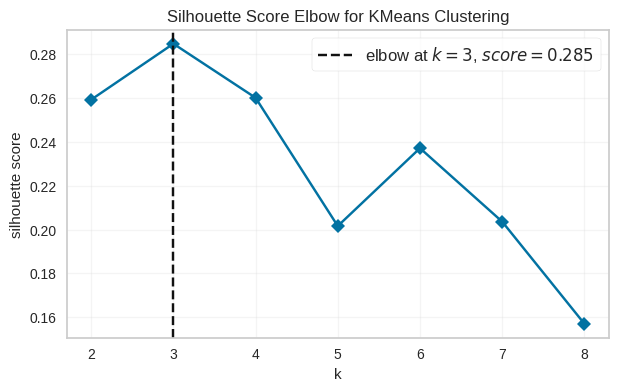

In [21]:
# Комірка безпечна для запуску навіть без необов'язкових пакетів.
try:
    from kneed import KneeLocator
    candidate_knee = KneeLocator(
        metrics_wine.index.to_list(), metrics_wine['WCSS'].to_list(),
        curve='convex', direction='decreasing'
    ).elbow
    print('kneed → кандидат K:', candidate_knee)
    if candidate_knee is None:
        print('Виразного перегину не виявлено; врахуйте інші критерії.')
except ImportError:
    print('Для KneeLocator: виконайте %pip install kneed, потім цю комірку.')

try:
    from yellowbrick.cluster import KElbowVisualizer
    from matplotlib import pyplot as plt
    plt.figure(figsize=(7, 4))
    visualizer = KElbowVisualizer(
        KMeans(n_init=10, random_state=RANDOM_STATE),
        k=(2, 9), metric='silhouette', timings=False
    )
    visualizer.fit(X_wine)
    print('Yellowbrick → кандидат K:', visualizer.elbow_value_)
    visualizer.show()
except ImportError:
    print('Для KElbowVisualizer: виконайте %pip install yellowbrick, потім цю комірку.')

## 4. Ієрархічна агломеративна кластеризація

**Відповідність лекції:** §4.

На початку кожна точка є окремим кластером. Надалі найближчі групи послідовно об'єднують. Правило **linkage** визначає міжкластерну відстань: `single`, `complete`, `average` або `ward`. Ward мінімізує приріст внутрішньокластерної суми квадратів (для евклідової геометрії).

**Дендрограма** відображає, на якій «висоті» об'єднувалися групи. Вона допомагає обрати число кластерів за горизонтальним зрізом дерева. Для наочності використаємо перші 45 стандартизованих спостережень Iris, а не всі 150 листків.

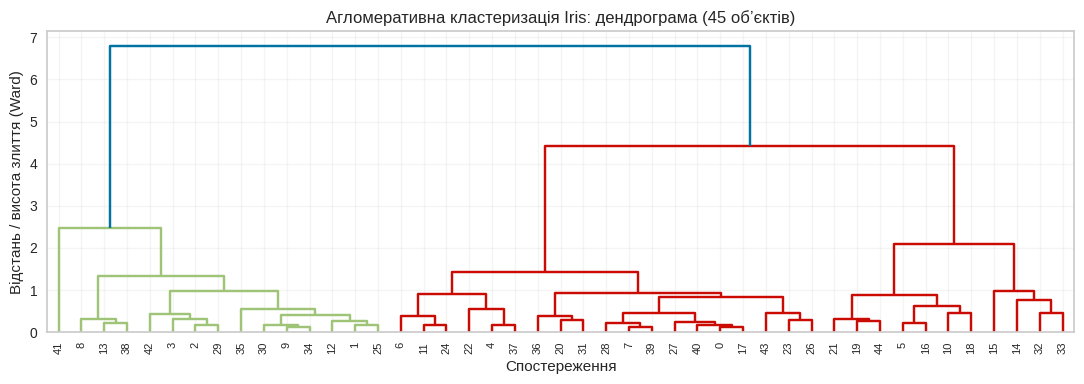

Розміри кластерів Ward: [71 49 30]
ARI(K-means, Ward): 0.626


In [22]:
Z_iris = linkage(X_iris[:45], method='ward')
plt.figure(figsize=(11, 4))
dendrogram(Z_iris, color_threshold=None, leaf_rotation=90)
plt.title('Агломеративна кластеризація Iris: дендрограма (45 об’єктів)')
plt.xlabel('Спостереження')
plt.ylabel('Відстань / висота злиття (Ward)')
plt.tight_layout()
plt.show()

agg_iris = AgglomerativeClustering(n_clusters=3, linkage='ward')
labels_iris_ward = agg_iris.fit_predict(X_iris)
print('Розміри кластерів Ward:', np.bincount(labels_iris_ward))
print('ARI(K-means, Ward):',
      round(adjusted_rand_score(labels_iris_km, labels_iris_ward), 3))

### 4.1. Що робити без наперед заданого K?

`AgglomerativeClustering` підтримує аргумент `distance_threshold`: якщо його задано, `n_clusters=None`. Тоді модель утворює число груп відповідно до порога, а не до фіксованого K.

In [23]:
threshold = float(np.percentile(Z_iris[:, 2], 85))
agg_threshold = AgglomerativeClustering(
    n_clusters=None, distance_threshold=threshold, linkage='ward'
)
labels_threshold = agg_threshold.fit_predict(X_iris[:45])
print('Висота зрізу:', round(threshold, 3))
print('Кількість знайдених груп:', np.unique(labels_threshold).size)

Висота зрізу: 0.981
Кількість знайдених груп: 8


## 5. Алгоритми щільнісної кластеризації

**Відповідність лекції:** §5.

`DBSCAN` використовує:
- `eps`: радіус околу точки;
- `min_samples`: мінімальна кількість об'єктів у ε-околі (включно з самою точкою) для базової точки.

Кластери утворюються із щільнісно зв'язаних точок. Мітка **−1** означає шум. На відміну від K-means, число кластерів не потрібно задавати заздалегідь, але воно залежить від параметрів щільності.

Використаємо **make_moons**: дві зігнуті групи, на яких сферичне припущення K-means може бути невдалим.

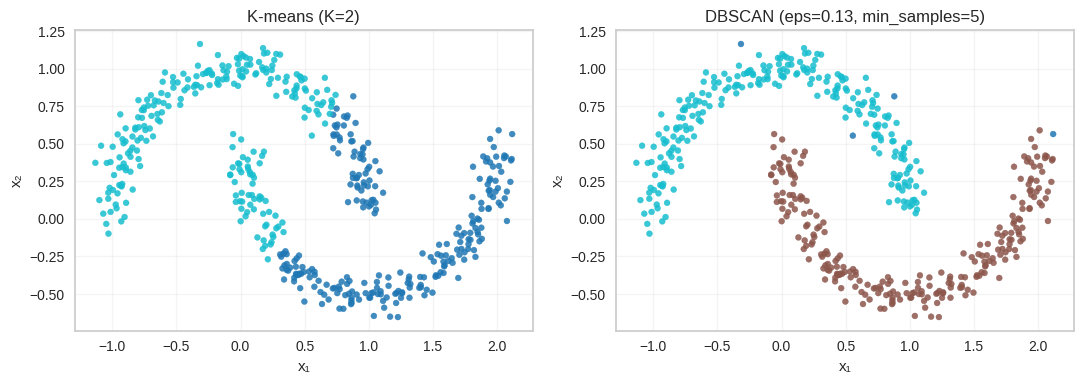

DBSCAN: кластерів 2, шумових точок 4 (0.8%)


In [24]:
X_moons, _ = make_moons(n_samples=500, noise=0.07,
                         random_state=RANDOM_STATE)
labels_moons_km = KMeans(n_clusters=2, n_init=10,
                         random_state=RANDOM_STATE).fit_predict(X_moons)
model_moons_dbscan = DBSCAN(eps=0.13, min_samples=5)
labels_moons_dbscan = model_moons_dbscan.fit_predict(X_moons)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, labs, title in zip(
    axes, [labels_moons_km, labels_moons_dbscan],
    ['K-means (K=2)', 'DBSCAN (eps=0.13, min_samples=5)']
):
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=labs,
               cmap='tab10', s=18, alpha=0.85)
    ax.set(title=title, xlabel='x₁', ylabel='x₂')
plt.tight_layout()
plt.show()

n_clusters = len(set(labels_moons_dbscan) - {-1})
noise_count = int((labels_moons_dbscan == -1).sum())
print(f'DBSCAN: кластерів {n_clusters}, шумових точок {noise_count} '
      f'({noise_count / len(X_moons):.1%})')

### 5.1. Як обрати `eps`: k-distance графік

Для кожної точки знаходимо відстань до `min_samples`-го найближчого сусіда. Після сортування відстаней шукаємо перехід до області різкого зростання. Це **евристика**, а не гарантований критерій оптимальності. Параметр `eps` має ті самі одиниці, що й відстані у просторі ознак.

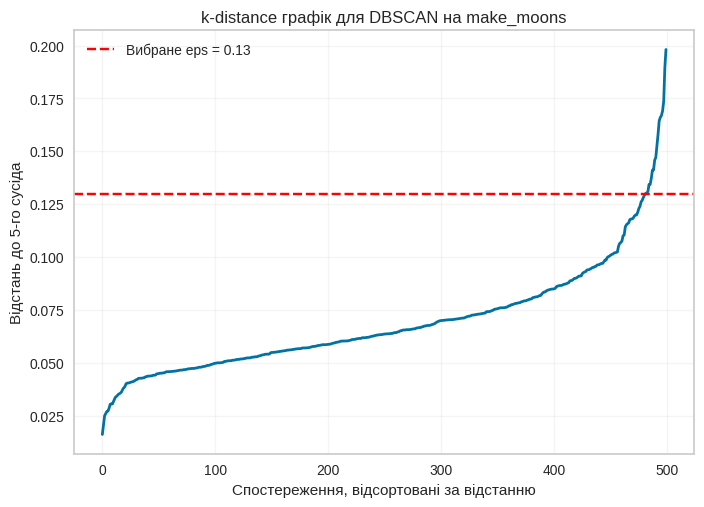

In [25]:
min_samples = 5
neighbors = NearestNeighbors(n_neighbors=min_samples).fit(X_moons)
distances, _ = neighbors.kneighbors(X_moons)
k_distances = np.sort(distances[:, -1])

plt.plot(k_distances, lw=2)
plt.axhline(0.13, linestyle='--', color='red', label='Вибране eps = 0.13')
plt.title('k-distance графік для DBSCAN на make_moons')
plt.xlabel('Спостереження, відсортовані за відстанню')
plt.ylabel(f'Відстань до {min_samples}-го сусіда')
plt.legend()
plt.show()

### 5.2. OPTICS та HDBSCAN

`OPTICS` аналізує щільнісну структуру на різних масштабах околу. `HDBSCAN` будує ієрархію щільнісних груп і виділяє стійкі кластери. Як і DBSCAN, ці алгоритми можуть залишати точки шумом. Приклад використовує **вбудований** `sklearn.cluster.HDBSCAN` (у сучасних версіях `scikit-learn`).

In [26]:
density_algorithms = {
    'DBSCAN': DBSCAN(eps=0.13, min_samples=5),
    'OPTICS': OPTICS(min_samples=8, min_cluster_size=20,
                     cluster_method='xi', xi=0.05),
    'HDBSCAN': HDBSCAN(min_cluster_size=20, min_samples=8, copy=True)
}
summary_density = []
for name, estimator in density_algorithms.items():
    labels = estimator.fit_predict(X_moons)
    summary_density.append({
        'Алгоритм': name,
        'Кластерів без шуму': len(set(labels) - {-1}),
        'Частка шуму': np.mean(labels == -1)
    })
display(pd.DataFrame(summary_density).round(3))

,Алгоритм,Кластерів без шуму,Частка шуму
0,DBSCAN,2,0.008
1,OPTICS,10,0.324
2,HDBSCAN,2,0.000


### 5.3. Коректне оцінювання результатів з шумом

Не слід механічно вважати `-1` «звичайним кластером». Наведений нижче силует обчислюємо **лише для точок, віднесених до кластерів**, і обов'язково вказуємо частку відкинутих спостережень. Якщо після відкидання шуму лишається менше двох груп, силует не визначений.

In [27]:
labels = labels_moons_dbscan
is_clustered = labels != -1
n_groups = np.unique(labels[is_clustered]).size
print(f'Частка шуму: {(~is_clustered).mean():.3f}')
if 2 <= n_groups < is_clustered.sum():
    score = silhouette_score(X_moons[is_clustered], labels[is_clustered])
    print(f'Силует тільки для не-шумових точок: {score:.3f}')
else:
    print('Силует не визначений: потрібні принаймні 2 коректні кластери.')

Частка шуму: 0.008
Силует тільки для не-шумових точок: 0.332


## 6. Інші алгоритми кластеризації

**Відповідність лекції:** §6.

`MeanShift` зсуває центри до локальних максимумів оціненої щільності, тому не вимагає попереднього K. `AffinityPropagation` передає «повідомлення» між об'єктами та визначає представників груп. `Birch` створює компактні підструктури, а `SpectralClustering` використовує спектральні властивості графа подібності.

**Пам'ятайте:** автоматично визначене число груп не означає автоматичну гарантію їхньої предметної якості.

MeanShift, bandwidth: 1.242
MeanShift, кількість кластерів: 3
AffinityPropagation, кількість кластерів на підвибірці: 3
Кількість представників: 3


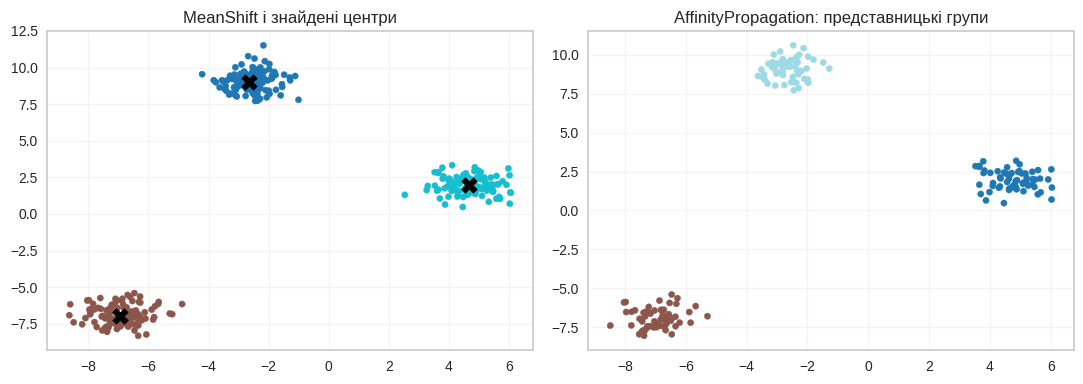

In [28]:
X_blobs, _ = make_blobs(n_samples=350, centers=3,
                        cluster_std=0.65, random_state=RANDOM_STATE)
bandwidth = estimate_bandwidth(X_blobs, quantile=0.20,
                               n_samples=250, random_state=RANDOM_STATE)
ms = MeanShift(bandwidth=bandwidth, bin_seeding=True)
labels_ms = ms.fit_predict(X_blobs)
print('MeanShift, bandwidth:', round(bandwidth, 3))
print('MeanShift, кількість кластерів:', len(set(labels_ms)))

ap = AffinityPropagation(random_state=RANDOM_STATE, damping=0.7)
labels_ap = ap.fit_predict(X_blobs[:180])
print('AffinityPropagation, кількість кластерів на підвибірці:',
      len(set(labels_ap)))
print('Кількість представників:', len(ap.cluster_centers_indices_))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c=labels_ms,
              cmap='tab10', s=20)
ax[0].scatter(ms.cluster_centers_[:, 0], ms.cluster_centers_[:, 1],
              color='black', marker='X', s=130)
ax[0].set_title('MeanShift і знайдені центри')
ax[1].scatter(X_blobs[:180, 0], X_blobs[:180, 1], c=labels_ap,
              cmap='tab20', s=20)
ax[1].set_title('AffinityPropagation: представницькі групи')
plt.tight_layout()
plt.show()

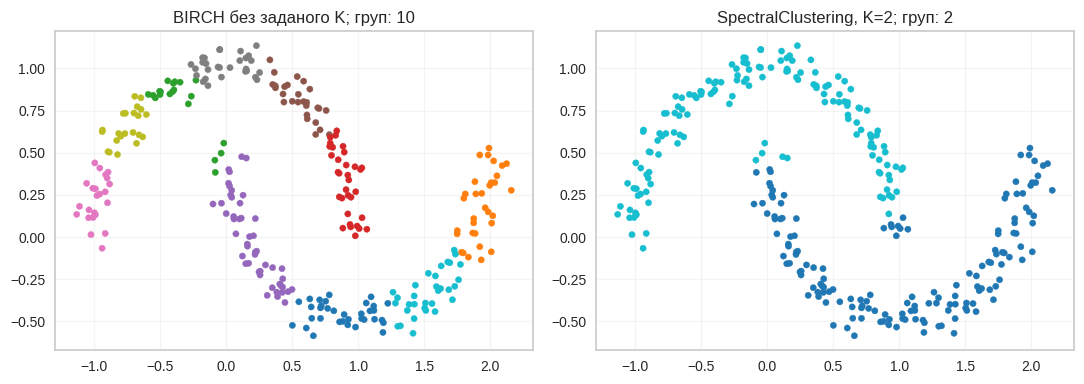

In [29]:
birch = Birch(threshold=0.3, n_clusters=None)
spectral = SpectralClustering(n_clusters=2, affinity='rbf',
                              gamma=10.0, random_state=RANDOM_STATE)
X_moons_small, _ = make_moons(n_samples=300, noise=0.06,
                              random_state=RANDOM_STATE)
labels_birch = birch.fit_predict(X_moons_small)
labels_spectral = spectral.fit_predict(X_moons_small)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for axes, labels, name in zip(ax, [labels_birch, labels_spectral],
                              ['BIRCH без заданого K', 'SpectralClustering, K=2']):
    axes.scatter(X_moons_small[:, 0], X_moons_small[:, 1],
                 c=labels, cmap='tab10', s=20)
    axes.set_title(f'{name}; груп: {len(set(labels))}')
plt.tight_layout()
plt.show()

## 7. Імовірнісна кластеризація: Gaussian Mixture Models

**Відповідність лекції:** §7.

На відміну від «жорстких» міток K-means, **GMM** оцінює умовні ймовірності належності точки до кожного гауссового компонента: `predict_proba(X)`.

$$p(x)=\sum_{k=1}^{K}\pi_k\,\mathcal N(x\mid\mu_k,\Sigma_k),\qquad\sum_k\pi_k=1.$$

У GMM кількість компонентів — не обов'язково кількість предметно змістовних груп. Навчання зазвичай ґрунтується на EM-подібному алгоритмі.

Ваги компонент: [0.25 0.25 0.25 0.25]
Форма матриці ймовірностей: (500, 4)
Ймовірності належності першого об’єкта: [0. 1. 0. 0.] | сума = 1.0


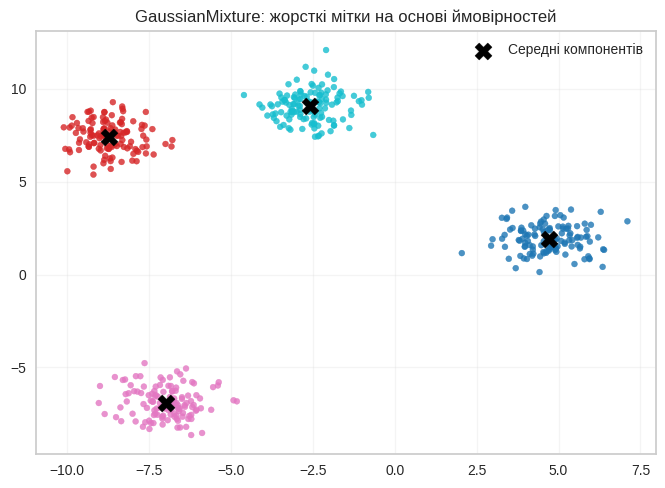

In [30]:
X_gmm, _ = make_blobs(n_samples=500, centers=4,
                      cluster_std=0.8, random_state=RANDOM_STATE)
gmm = GaussianMixture(n_components=4, covariance_type='full',
                      n_init=3, random_state=RANDOM_STATE)
gmm.fit(X_gmm)
labels_gmm = gmm.predict(X_gmm)
proba_gmm = gmm.predict_proba(X_gmm)

print('Ваги компонент:', np.round(gmm.weights_, 3))
print('Форма матриці ймовірностей:', proba_gmm.shape)
print('Ймовірності належності першого об’єкта:',
      np.round(proba_gmm[0], 3), '| сума =', round(proba_gmm[0].sum(), 4))

plt.scatter(X_gmm[:, 0], X_gmm[:, 1], c=labels_gmm,
            cmap='tab10', s=18, alpha=0.8)
plt.scatter(gmm.means_[:, 0], gmm.means_[:, 1],
            marker='X', color='black', s=150, label='Середні компонентів')
plt.title('GaussianMixture: жорсткі мітки на основі ймовірностей')
plt.legend()
plt.show()

### 7.1. Автоматизований добір числа компонент за AIC/BIC

`GaussianMixture` має методи `.aic(X)` і `.bic(X)`: **менше значення — краще** у межах порівнюваних моделей. BIC зазвичай сильніше штрафує складність, ніж AIC, за достатньо великої вибірки. Це критерії вибору **ймовірнісної моделі**, а не прямі аналоги WCSS.

,AIC,BIC
Компонентів,,
1,6340.5,6361.5
2,4924.2,4970.5
3,4157.6,4229.3
4,3761.7,3858.7
5,3765.8,3888.0
6,3773.9,3921.4
7,3775.6,3948.4
8,3785.0,3983.0


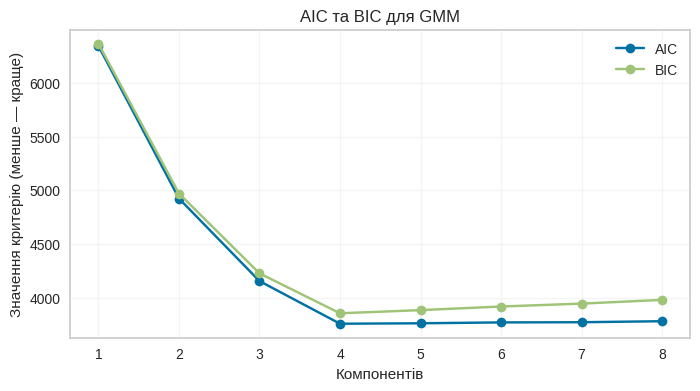

Кандидат за AIC: 4
Кандидат за BIC: 4


In [31]:
gmm_scores = []
for n in range(1, 9):
    gm = GaussianMixture(n_components=n, covariance_type='full',
                         n_init=3, random_state=RANDOM_STATE)
    gm.fit(X_gmm)
    gmm_scores.append({'Компонентів': n,
                       'AIC': gm.aic(X_gmm), 'BIC': gm.bic(X_gmm)})
score_table = pd.DataFrame(gmm_scores).set_index('Компонентів')
display(score_table.round(1))

score_table.plot(marker='o', figsize=(8, 4), title='AIC та BIC для GMM')
plt.xticks(score_table.index)
plt.ylabel('Значення критерію (менше — краще)')
plt.show()

print('Кандидат за AIC:', score_table['AIC'].idxmin())
print('Кандидат за BIC:', score_table['BIC'].idxmin())

### 7.2. BayesianGaussianMixture

Тут `n_components` визначає **верхню межу** числа компонентів; ваги зайвих компонентів можуть наближатися до нуля. Поріг `0.01` нижче є лише практичною умовою для підрахунку «активних» компонентів, а не строгим статистичним правилом.

In [32]:
bgm = BayesianGaussianMixture(
    n_components=10, weight_concentration_prior_type='dirichlet_process',
    random_state=RANDOM_STATE, max_iter=500
)
bgm.fit(X_gmm)
print('Ваги 10 компонент:', np.round(bgm.weights_, 3))
print('Число компонент із вагою понад 1%:', int((bgm.weights_ > 0.01).sum()))

Ваги 10 компонент: [0.002 0.002 0.25  0.25  0.249 0.247 0.    0.    0.    0.   ]
Число компонент із вагою понад 1%: 4


## 8. Перевірка якості та стабільності

**Відповідність лекції:** §9, §11.

Внутрішні індекси (`silhouette_score`, `calinski_harabasz_score`, `davies_bouldin_score`) працюють без еталонних міток. Зовнішні індекси (`adjusted_rand_score`, `adjusted_mutual_info_score`) можна обчислювати **після** кластеризації, якщо незалежні відомі категорії є в навчальному датасеті.

Числа 0, 1, 2 у мітках кластерів — умовні. Перестановка номерів не означає зміну розбиття; ARI до такої перестановки інваріантний.

In [33]:
print('Iris: ARI до відомих міток =',
      round(adjusted_rand_score(y_iris_reference, labels_iris_km), 3))
print('Iris: AMI до відомих міток =',
      round(adjusted_mutual_info_score(y_iris_reference, labels_iris_km), 3))

permuted = np.array([2, 0, 1])[labels_iris_km]
print('ARI після перестановки номерів кластерів =',
      adjusted_rand_score(labels_iris_km, permuted))

Iris: ARI до відомих міток = 0.62
Iris: AMI до відомих міток = 0.655
ARI після перестановки номерів кластерів = 1.0


### 8.1. Чутливість до ініціалізації

Для K-means треба зафіксувати `random_state` і `n_init`, а під час дослідження стійкості — **свідомо змінювати** ініціалізацію. Якщо різні запуски дають однакову інерцію й ARI близький до 1, це один з аргументів на користь стійкості розбиття, але не гарантія його прикладної корисності.

In [34]:
stability_labels = []
stability_rows = []
for seed in [7, 21, 42, 101, 202]:
    model = KMeans(n_clusters=3, n_init=1, random_state=seed)
    labels = model.fit_predict(X_wine)
    stability_labels.append(labels)
    stability_rows.append({'random_state': seed, 'WCSS': model.inertia_,
                           'Silhouette': silhouette_score(X_wine, labels)})
print('Порівняння запусків із n_init=1:')
display(pd.DataFrame(stability_rows).round(3))
print('ARI між першим запуском і рештою:',
      [round(adjusted_rand_score(stability_labels[0], labs), 3)
       for labs in stability_labels[1:]])

Порівняння запусків із n_init=1:


,random_state,WCSS,Silhouette
0,7,1278.761,0.286
1,21,1277.928,0.285
2,42,1277.928,0.285
3,101,1277.928,0.285
4,202,1279.731,0.283


ARI між першим запуском і рештою: [0.982, 0.982, 0.982, 0.947]


## 9. Наскрізний приклад: змістовна інтерпретація кластерів Wine

**Відповідність лекції:** §10.

Порівняння геометричних індексів — **не кінцева мета**. Для предметного висновку потрібно:

1. обґрунтувати кандидатне K за кількома критеріями;
2. побудувати кластеризацію на стандартизованих ознаках;
3. повернутися до початкових одиниць вимірювання і проаналізувати типові значення ознак;
4. повідомити розміри кластерів, а також результати альтернативного алгоритму.

Нижче для *ілюстрації профілювання* використаємо `K=3`. Це не твердження, що три групи завжди оптимальні за кожним індексом.

In [35]:
k_wine_demo = 3
wine_model = KMeans(n_clusters=k_wine_demo, n_init=10,
                    random_state=RANDOM_STATE)
labels_wine_demo = wine_model.fit_predict(X_wine)

profile_wine = (features_wine.assign(cluster=labels_wine_demo)
                .groupby('cluster').mean())
sizes_wine = pd.Series(labels_wine_demo).value_counts().sort_index()
center_original_units = pd.DataFrame(
    scaler_wine.inverse_transform(wine_model.cluster_centers_),
    columns=features_wine.columns
)

print('Кількість об’єктів за групами:')
display(sizes_wine.rename('Кількість').to_frame())
print('Середній профіль (в оригінальних одиницях):')
display(profile_wine[['alcohol', 'flavanoids', 'proline']].round(2))
print('Центри зворотно перетворені в початковий масштаб:')
display(center_original_units[['alcohol', 'flavanoids', 'proline']].round(2))

Кількість об’єктів за групами:


,Кількість
0,65
1,51
2,62


Середній профіль (в оригінальних одиницях):


,alcohol,flavanoids,proline
cluster,,,
0,12.25,2.05,510.17
1,13.13,0.82,619.06
2,13.68,3.00,1100.23


Центри зворотно перетворені в початковий масштаб:


,alcohol,flavanoids,proline
0,12.25,2.05,510.17
1,13.13,0.82,619.06
2,13.68,3.00,1100.23


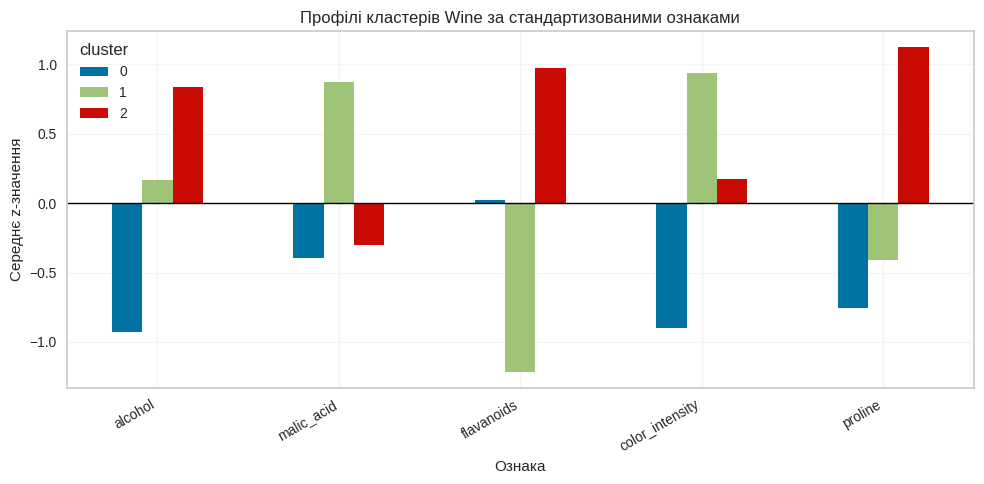

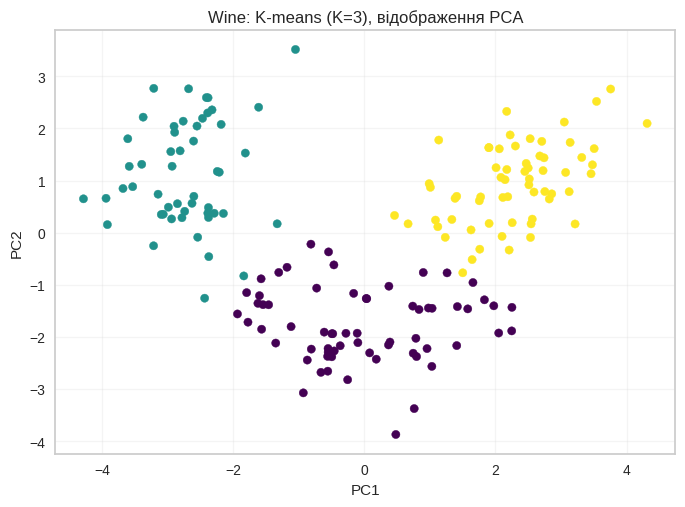

In [36]:
# Профілі стандартизованих середніх: значення > 0 вище за середнє у вибірці.
profile_scaled = pd.DataFrame(X_wine, columns=features_wine.columns)
profile_scaled['cluster'] = labels_wine_demo
profile_scaled = profile_scaled.groupby('cluster').mean()

selected_features = ['alcohol', 'malic_acid', 'flavanoids', 'color_intensity', 'proline']
profile_scaled[selected_features].T.plot(kind='bar', figsize=(10, 5))
plt.axhline(0, color='black', linewidth=1)
plt.title('Профілі кластерів Wine за стандартизованими ознаками')
plt.ylabel('Середнє z-значення')
plt.xlabel('Ознака')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

wine_2d = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X_wine)
plt.scatter(wine_2d[:, 0], wine_2d[:, 1], c=labels_wine_demo,
            cmap='viridis', s=35)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Wine: K-means (K=3), відображення PCA')
plt.show()

### 9.1. Порівняння з Ward і DBSCAN

Щоб порівнювати алгоритми коректно, застосовуємо **одні й ті самі стандартизовані дані**. `ARI` нижче вимірює узгодженість двох кластерних розбиттів, а не «точність» одного з них. Для DBSCAN додатково вказуємо частку шуму.

ARI між K-means і Ward: 0.853
DBSCAN → груп без шуму: 2
DBSCAN → частка шуму: 0.309


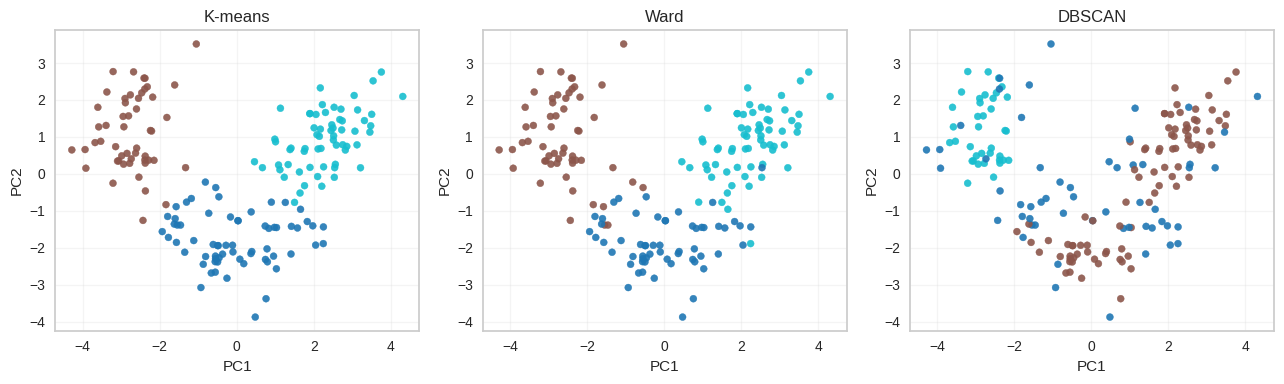

In [37]:
labels_wine_ward = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_wine)
labels_wine_db = DBSCAN(eps=2.2, min_samples=5).fit_predict(X_wine)

print('ARI між K-means і Ward:',
      round(adjusted_rand_score(labels_wine_demo, labels_wine_ward), 3))
print('DBSCAN → груп без шуму:', len(set(labels_wine_db) - {-1}))
print('DBSCAN → частка шуму:', round(np.mean(labels_wine_db == -1), 3))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for axes, labels, name in zip(ax,
    [labels_wine_demo, labels_wine_ward, labels_wine_db],
    ['K-means', 'Ward', 'DBSCAN']):
    axes.scatter(wine_2d[:, 0], wine_2d[:, 1], c=labels,
                 cmap='tab10', s=25, alpha=0.9)
    axes.set(title=name, xlabel='PC1', ylabel='PC2')
plt.tight_layout()
plt.show()

## 10. Підсумок навчального прикладу

**У цьому ноутбуці продемонстровано:**

| Призначення | Алгоритм / метод | Вбудований інструмент |
|:--|:--|:--|
| Центроїдна кластеризація | K-means | `KMeans`, `.labels_`, `.cluster_centers_`, `.inertia_` |
| Прискорення / поділ груп | Mini-batch / bisecting | `MiniBatchKMeans`, `BisectingKMeans` |
| Ієрархія | Ward + дендрограма | `AgglomerativeClustering`, `scipy.cluster.hierarchy` |
| Щільність | DBSCAN, OPTICS, HDBSCAN | `DBSCAN`, `OPTICS`, `HDBSCAN` |
| Моди щільності | Mean Shift | `MeanShift`, `estimate_bandwidth` |
| Альтернативні підходи | Affinity, BIRCH, Spectral | однойменні класи `sklearn.cluster` |
| Імовірнісні компоненти | GMM | `GaussianMixture`, `.aic()`, `.bic()` |
| Неефективні компоненти | Bayesian GMM | `BayesianGaussianMixture`, `.weights_` |
| Вибір K / якість | лікоть, силует, CH, DB | `.inertia_`, `silhouette_score`, `calinski_harabasz_score`, `davies_bouldin_score` |
| Автоматизація аналізу ліктя | KneeLocator, Yellowbrick | *додаткові* `kneed` і `yellowbrick` |

**Головний методичний висновок:** жоден внутрішній індекс окремо не гарантує «правильного» $K$. Обґрунтовуйте вибір через кілька критеріїв, властивості даних, стійкість груп і змістовність їхніх профілів. Не плутайте номер кластера з реальною категорією.

---
# Самостійне завдання для студентів — одне комплексне завдання

## Дослідження кластерної структури рукописних цифр (`load_digits`)

**Мета:** самостійно провести повний цикл кластеризації на **новому** вбудованому наборі даних, який не використовувався в демонстраційних прикладах ноутбука і не збігається з лабораторною роботою про опосумів.

**Умова завдання.** Завантажте `sklearn.datasets.load_digits` (1797 зображень рукописних цифр, кожне подано 64 числовими ознаками). Розглядайте це як **задачу навчання без учителя**: під час вибору числа кластерів та навчання **не використовуйте** еталонні значення цифр `target`.

Виконайте повний аналіз: перевірте структуру й масштаб ознак, за потреби виконайте стандартизацію; дослідіть `KMeans` на діапазоні $K=2,\ldots,12$; побудуйте графік ліктя та графіки силуету, CH і DB; обґрунтуйте одне кандидатне число кластерів (розбіжності критеріїв треба пояснити); побудуйте фінальне розбиття й порівняйте його з `AgglomerativeClustering`; відобразіть точки в PCA-проєкції та оцініть розміри отриманих груп. **Лише після завершення кластеризації** можете використати відомі мітки `target` для додаткового розрахунку ARI й пояснити, чому отримані кластери не зобов'язані відповідати десяти цифрам.

**Результат здачі:** один виконаний `.ipynb` із кодом, графіками, таблицею критеріїв та коротким академічним висновком (8–12 речень), у якому наведено обране $K$, аргументи на користь вибору, порівняння двох алгоритмів та застереження щодо інтерпретації.

> Самостійний етап навмисно **не містить готового розв'язання**. Наступна комірка лише завантажує дані; весь аналіз студент пише самостійно.

In [38]:
# Початкова комірка самостійного завдання (без розв'язання)
from sklearn.datasets import load_digits

digits = load_digits()
X_digits_raw = digits.data
# y_digits_reference = digits.target  # НЕ використовувати до завершення кластеризації!

print('Розмірність даних:', X_digits_raw.shape)
print('Початковий діапазон значень:', X_digits_raw.min(), '...', X_digits_raw.max())
# Далі: ваш код дослідження, візуалізації, оцінювання та висновків.

Розмірність даних: (1797, 64)
Початковий діапазон значень: 0.0 ... 16.0


In [40]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_digits_raw)

metrics_list = []
K_range = range(2, 13)

for k in K_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)

    metrics_list.append({
        'K': k,
        'WCSS (Inertia)': kmeans.inertia_,
        'Silhouette': silhouette_score(X_scaled, labels),
        'CH Score': calinski_harabasz_score(X_scaled, labels),
        'DB Score': davies_bouldin_score(X_scaled, labels)
    })

metrics_df = pd.DataFrame(metrics_list).set_index('K')
display(metrics_df.round(3))

,WCSS (Inertia),Silhouette,CH Score,DB Score
K,,,,
2,100423.843,0.106,164.321,2.964
3,93842.483,0.105,150.782,2.743
4,89213.968,0.095,136.685,2.511
5,85096.055,0.102,129.094,2.253
6,81678.467,0.099,122.524,2.261
7,77749.328,0.113,122.280,2.072
8,74854.159,0.127,118.689,2.016
9,72029.725,0.136,116.629,1.982
10,69813.559,0.139,113.204,1.877


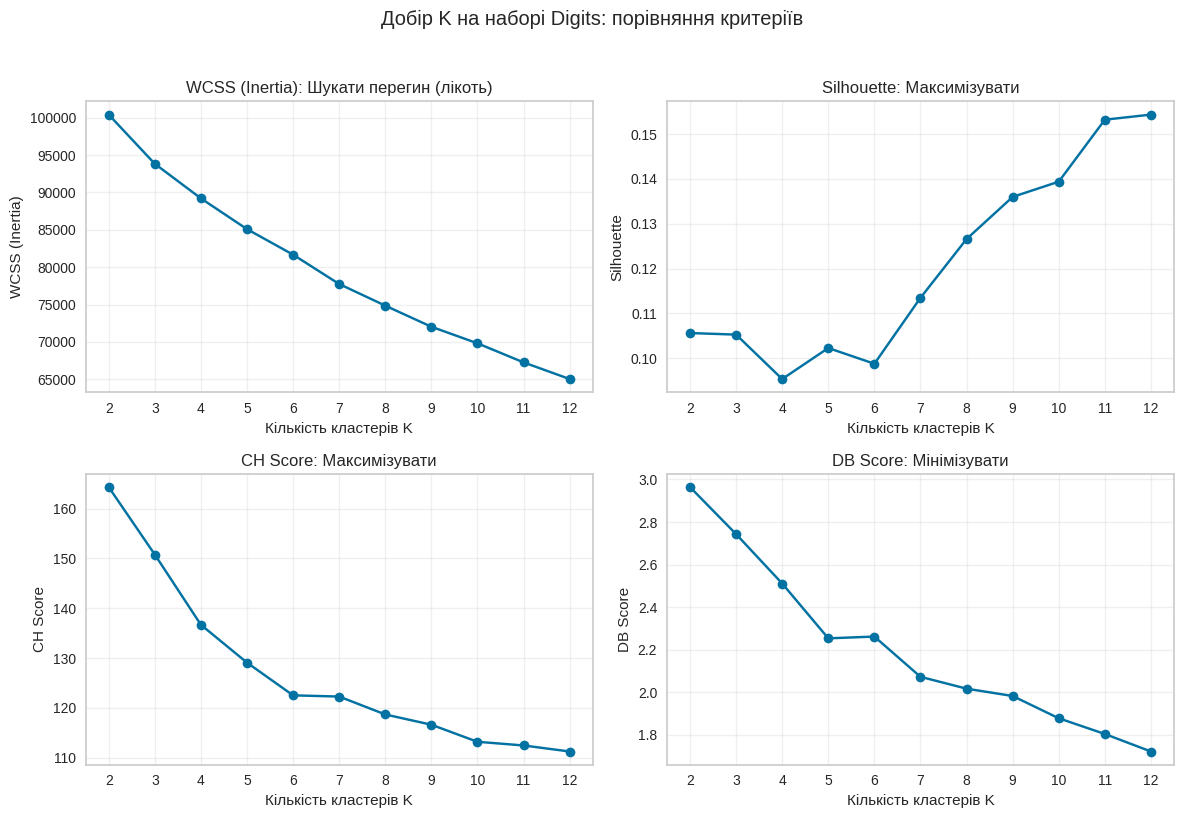

In [41]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, metric, prefer in zip(
    axes.flat,
    ['WCSS (Inertia)', 'Silhouette', 'CH Score', 'DB Score'],
    ['Шукати перегин (лікоть)', 'Максимізувати', 'Максимізувати', 'Мінімізувати']
):
    ax.plot(metrics_df.index, metrics_df[metric], marker='o')
    ax.set(title=f'{metric}: {prefer}', xlabel='Кількість кластерів K', ylabel=metric)
    ax.set_xticks(metrics_df.index)
    ax.grid(True, alpha=0.3)

fig.suptitle('Добір K на наборі Digits: порівняння критеріїв', y=1.02)
plt.tight_layout()
plt.show()

Обґрунтування для вибору кандидата K:
Суто за математичними індексами Silhouette та DB найкращим кандидатом виглядає K=12. Проте, знаючи предметну область датасету (рукописні арабські цифри від 0 до 9), найдоцільніше обрати K=10. Виправдати це можна тим, що при K=10 значення силуету є високим (майже 0.14) і продовжує зростати, а DB стабільно зменшується, забезпечуючи компроміс між математичними метриками та фізичним змістом даних.

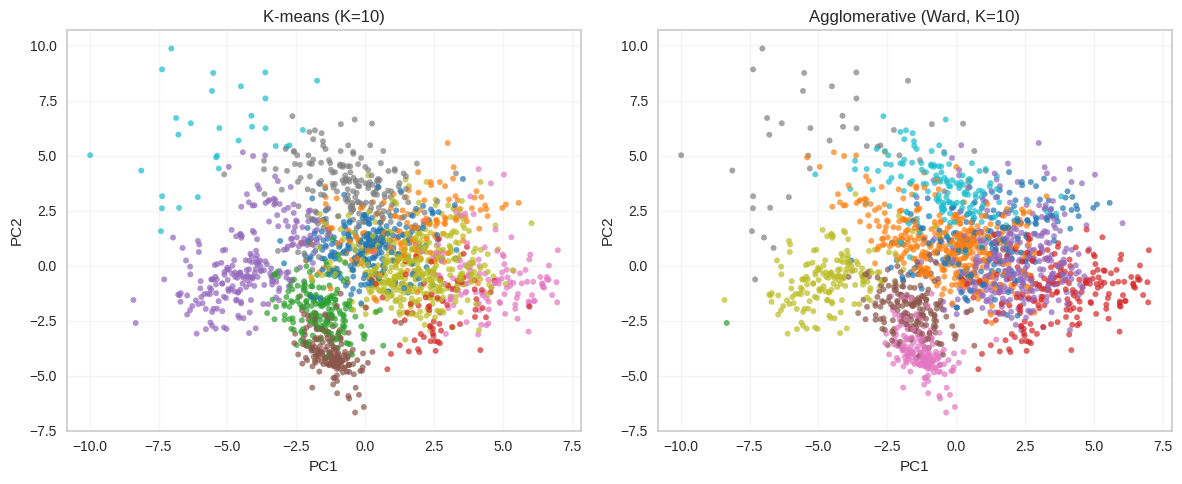

ARI для K-means: 0.534
ARI для Agglomerative (Ward): 0.664


In [42]:
k_final = 10
kmeans_final = KMeans(n_clusters=k_final, n_init=10, random_state=42)
labels_km = kmeans_final.fit_predict(X_scaled)

agg_final = AgglomerativeClustering(n_clusters=k_final, linkage='ward')
labels_agg = agg_final.fit_predict(X_scaled)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_km, cmap='tab10', s=15, alpha=0.7)
axes[0].set_title('K-means (K=10)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')

axes[1].scatter(X_pca[:, 0], X_pca[:, 1], c=labels_agg, cmap='tab10', s=15, alpha=0.7)
axes[1].set_title('Agglomerative (Ward, K=10)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

plt.tight_layout()
plt.show()

y_digits_reference = digits.target
ari_km = adjusted_rand_score(y_digits_reference, labels_km)
ari_agg = adjusted_rand_score(y_digits_reference, labels_agg)

print(f"ARI для K-means: {ari_km:.3f}")
print(f"ARI для Agglomerative (Ward): {ari_agg:.3f}")

У результаті проведеного аналізу кластерної структури набору даних load_digits оптимальною кількістю кластерів було обрано K=10. Хоча внутрішні геометричні метрики (Silhouette та Davies-Bouldin) вказували на суто математичний оптимум при K=12, вибір K=10 обґрунтовано предметною областю датасету (10 унікальних цифр), а також стабільним показником силуету на цьому рівні. Візуалізація через PCA-проєкцію підтвердила суттєве перекриття груп у двовимірному просторі, що свідчить про складну багатовимірну структуру ознак. Завершальне порівняння алгоритмів за допомогою еталонних міток продемонструвало перевагу ієрархічного підходу: метод AgglomerativeClustering (Ward) досяг значення ARI 0.664, перевершивши базовий центроїдний K-means із показником 0.534. Це вказує на те, що ієрархічне злиття груп краще вловлює варіативність написання цифр, ніж поділ на сферичні центроїди. Водночас отримані кластери не збігаються з реальними категоріями ідеально (ARI < 1). Це пояснюється тим, що алгоритми навчання без учителя групують об'єкти виключно за математичною близькістю інтенсивності пікселів. Відтак, різні стилі написання однієї цифри алгоритм може розділити, а візуально схожі цифри (наприклад, 1 і 7) - помилково об'єднати.